# 4 · Hourly rain from your own archive

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/agent-engineering-studio/dpc-radar/blob/main/notebooks/04_hourly_rain_archive.ipynb)

Two facts make this notebook necessary.

1. **The DPC deletes each frame after about five months.** Nobody keeps a public archive of
   the «Merging». What you do not save in time is gone.
2. **The shortest «Merging» is three hours long** (`CUM3`). Floods and landslides are decided
   by the rain of a single hour.

`dpc_radar.archive` answers both: it saves the frames on your disk, and from them it rebuilds
the rain **hour by hour, corrected with the gauges**.

> The frames of this example (10 October 2026) are kept by the DPC until about March 2027.
> After that, change `START` and `END` to recent days.

In [1]:
# On Colab (or any fresh environment) this installs the library; at home it does nothing.
import importlib.util

if importlib.util.find_spec("dpc_radar") is None:
    %pip install -q "dpc-radar[bulletins]" matplotlib

## Save a day of frames

`archive` downloads the frames of a time range that are not on disk yet: `CUM3` every three
hours and `SRT1` every hour. `limit` is the largest number of requests it may make: be kind
to a public service.

In [2]:
from datetime import UTC, datetime
from pathlib import Path

from dpc_radar import RadarClient
from dpc_radar.archive import MergingArchive, archive

FOLDER = Path("data/archive")
START = datetime(2026, 10, 10, 0, tzinfo=UTC)
END = datetime(2026, 10, 11, 0, tzinfo=UTC)

async with RadarClient() as radar:
    report = await archive(FOLDER, radar, start=START, end=END, limit=60)
print(report)

ArchiveReport(downloaded=0, present=34, lost=0, failed=0, bytes=0)


Run the cell again: `downloaded` becomes 0 and `present` goes up. The archive never downloads
a frame twice, so the same line can run every night from a scheduler (see
[`examples/nightly_archive.py`](../examples/nightly_archive.py)).

On disk it is plain GeoTIFF files, one per frame, in folders by product and day. Any GIS
program opens them.

In [3]:
files = sorted(FOLDER.rglob("*.tif"))
print(len(files), "frames,", round(sum(f.stat().st_size for f in files) / 1e6, 1), "MB")
for file in files[:3] + files[-3:]:
    print("  ", file)

34 frames, 33.5 MB
   data/archive/CUM3/2026/10/10/CUM3_202610100000.tif
   data/archive/CUM3/2026/10/10/CUM3_202610100300.tif
   data/archive/CUM3/2026/10/10/CUM3_202610100600.tif
   data/archive/SRT1/2026/10/10/SRT1_202610102200.tif
   data/archive/SRT1/2026/10/10/SRT1_202610102300.tif
   data/archive/SRT1/2026/10/11/SRT1_202610110000.tif


## From three-hour blocks to single hours

The trick is simple, and it is the heart of the module:

- the «Merging» block says **how much** fell in three hours (radar and gauges);
- the radar says **when**: how those three hours share the rain.

Each hour gets its share of the block, in proportion to what the radar saw. The three hours
still add up exactly to the «Merging».

In [4]:
place = [(15.78, 37.92)]  # Melito di Porto Salvo
store = MergingArchive(FOLDER)

corrected = store.hourly(place, START, END)
hours = sorted(corrected)
with_gauges = [corrected[h][0] or 0.0 for h in hours]
radar_only = [(store.read("SRT1", h).sample(place)[0] or 0.0) for h in hours]

print(f"{'hour (UTC)':<12}{'radar':>8}{'corrected':>12}")
for h, r, c in zip(hours, radar_only, with_gauges, strict=True):
    if c >= 1:
        print(f"{h:%d %b %H:%M}  {r:6.1f}  {c:10.1f}  {'#' * round(c / 2)}")
print(f"{'day':<12}{sum(radar_only):8.0f}{sum(with_gauges):12.0f}  mm")

hour (UTC)     radar   corrected
10 Oct 01:00    16.0        47.4  ########################
10 Oct 02:00    21.2        63.0  ################################
10 Oct 03:00     8.3        24.6  ############
10 Oct 04:00    20.3         6.3  ###
10 Oct 05:00    17.7         5.5  ###
10 Oct 06:00     5.4         1.7  #
10 Oct 10:00     6.2         1.6  #
10 Oct 13:00     0.6         1.4  #
10 Oct 14:00     1.9         5.0  ##
10 Oct 15:00     3.0         7.8  ####
10 Oct 16:00     8.4        22.1  ###########
10 Oct 17:00     1.1         3.0  ##
day              115         190  mm


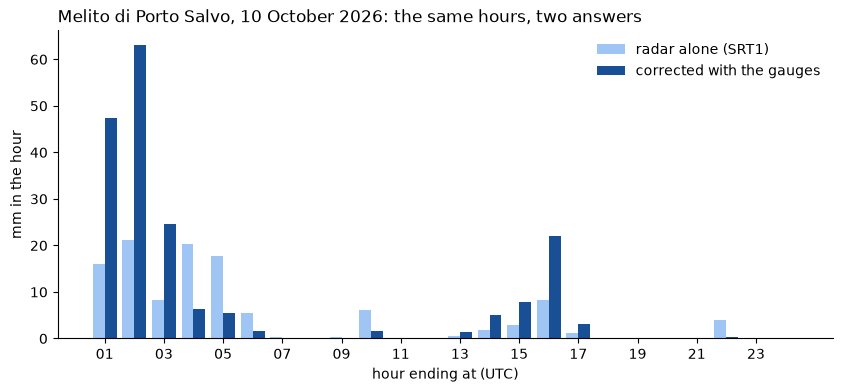

In [5]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(hours))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, radar_only, width=0.4, color="#9ec5f4", label="radar alone (SRT1)")
ax.bar(x + 0.2, with_gauges, width=0.4, color="#184f95", label="corrected with the gauges")
ax.set_xticks(x[::2], [f"{h:%H}" for h in hours[::2]])
ax.set_xlabel("hour ending at (UTC)")
ax.set_ylabel("mm in the hour")
ax.set_title("Melito di Porto Salvo, 10 October 2026: the same hours, two answers", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

Look at the first three hours: the gauges gave back the water the radar had lost, and the
bars triple. Between 03:00 and 06:00 the opposite happens: the radar saw more than fell on
the ground, and the bars shrink. The correction works in both directions. Inside each block
of three hours, the **shape** is still the radar's.

## Why an hour matters

A threshold for flash floods is usually written per hour (Limen, the project this library
was born for, raises its first flag at 30 mm in one hour). Count the hours over it, with and
without the correction.

In [6]:
THRESHOLD = 30.0  # mm in one hour
print("hours over", THRESHOLD, "mm")
print("  radar alone :", sum(r >= THRESHOLD for r in radar_only))
print("  corrected   :", sum(c >= THRESHOLD for c in with_gauges))
print(f"worst hour: {max(radar_only):.0f} mm (radar) -> {max(with_gauges):.0f} mm (corrected)")

hours over 30.0 mm
  radar alone : 0
  corrected   : 2
worst hour: 21 mm (radar) -> 63 mm (corrected)


## What you have seen

- `archive(folder, radar, start=, end=, limit=)` saves the frames before the DPC deletes them;
- `MergingArchive(folder).hourly(points, start, end)` gives rain per hour, corrected with the
  gauges, for any list of points;
- an hour that nobody measured comes back as `None`, never as zero.

Years of such an archive are what a model needs to learn from past storms. For the years
before your archive there is the radar-only history 2010–2025 (`dpc_radar.history`, 50 GB
from Zenodo): see the README.

**Next:** [5 · The official alert, next to the radar](05_alert_vs_radar.ipynb).

*Radar data © Dipartimento della Protezione Civile, CC BY-SA 4.0.*